In [1]:
import sys; print(sys.executable)

/home/noir/ai-engineering-from-scratch/.venv/bin/python


In [2]:
import numpy as np
data = np.random.randn(1000)
data.mean(), data.std()

(np.float64(0.014638425273983513), np.float64(1.0281496000141221))

In [3]:
import numpy as np
data = np.random.randn(1000)
data.mean(), data.std()

(np.float64(-0.015637286074737047), np.float64(1.0018171400611613))

In [4]:
%timeit np.random.randn(10000)

174 μs ± 2.1 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [5]:
%%time
a = np.random.randn(3000, 3000)
b = np.random.randn(3000, 3000)
c = a @ b

CPU times: user 7.63 s, sys: 851 ms, total: 8.48 s
Wall time: 743 ms


In [6]:
%%time
total = sum(i * i for i in range(5_000_000))
print("Tổng:", total)

Tổng: 41666654166667500000
CPU times: user 2.52 s, sys: 14.3 ms, total: 2.54 s
Wall time: 299 ms


In [7]:
%matplotlib inline

In [9]:
import pandas as pd

df = pd.DataFrame({
    "model": ["Linear", "Random Forest", "Neural Net"],
    "accuracy": [0.72, 0.89, 0.94],
    "training_time": [0.1, 2.3, 45.6]
})
df

,model,accuracy,training_time
0,Linear,0.72,0.1
1,Random Forest,0.89,2.3
2,Neural Net,0.94,45.6


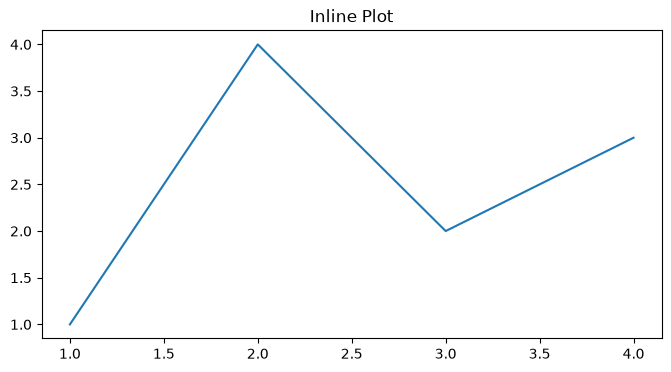

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot([1, 2, 3, 4], [1, 4, 2, 3])
plt.title("Inline Plot")
plt.show()

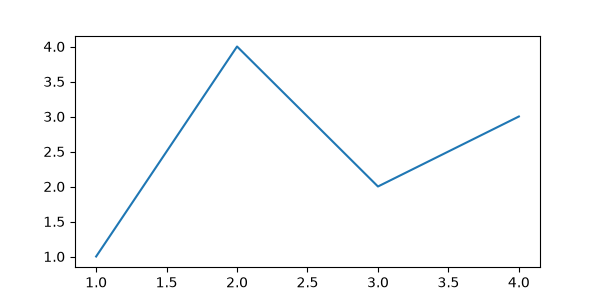

In [11]:
from IPython.display import Image, display

plt.figure(figsize=(6, 3))
plt.plot([1, 2, 3, 4], [1, 4, 2, 3])
plt.savefig("architecture.png")
plt.close()

display(Image(filename="architecture.png"))

In [12]:
import sys
!uv pip install --python {sys.executable} scikit-learn

Using Python 3.12.16 environment at: /home/noir/ai-engineering-from-scratch/.venv
Checked 1 package in 11ms


In [13]:
import random
import numpy as np
%timeit [random.random() for _ in range(1000000)]
%timeit np.random.rand(100000)

55.5 ms ± 2.39 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
530 μs ± 8.16 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


# Phân tích nhật ký huấn luyện mô hình
Notebook này tải dữ liệu từ tệp CSV, hiển thị bảng DataFrame và vẽ biểu đồ theo dõi quá trình huấn luyện.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Tạo sẵn tệp CSV mẫu để notebook luôn tự chạy độc lập từ đầu đến cuối
csv_data = """epoch,train_loss,val_accuracy
1,0.92,0.64
2,0.68,0.75
3,0.49,0.82
4,0.35,0.87
5,0.24,0.91
"""

with open("training_metrics.csv", "w") as f:
    f.write(csv_data)

# Đọc dữ liệu từ tệp CSV
df = pd.read_csv("training_metrics.csv")

## 1. Hiển thị dữ liệu DataFrame

In [15]:
df

,epoch,train_loss,val_accuracy
0,1,0.92,0.64
1,2,0.68,0.75
2,3,0.49,0.82
3,4,0.35,0.87
4,5,0.24,0.91


## 2. Trực quan hóa kết quả huấn luyện

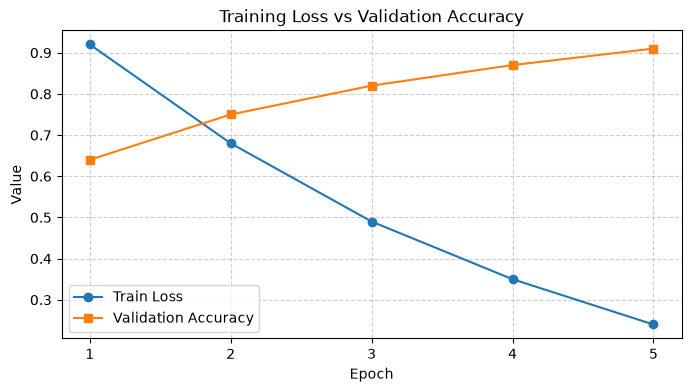

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(df["epoch"], df["train_loss"], marker="o", label="Train Loss")
plt.plot(df["epoch"], df["val_accuracy"], marker="s", label="Validation Accuracy")
plt.title("Training Loss vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.xticks(df["epoch"])
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()